<a href="https://colab.research.google.com/github/dakshasingh06/hcl-project/blob/main/Project_21_Online_Retail_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Project 21 — Online Retail Customer Purchase Analysis
**Industry:** Retail / E-Commerce  |  **Level:** Beginner  |  **Tools:** Core Python · NumPy · Pandas · Matplotlib

**Business scenario:** analyse customer orders, product categories, quantities and payment details to understand buying patterns and improve sales.

### ▶️ How to run (Google Colab)
1. Click **Runtime → Run all** (or press `Ctrl/Cmd + F9`). Nothing needs to be uploaded or installed — the dataset is embedded in this notebook.
2. To use your own CSV instead, set `DATA_SOURCE = "upload"` in the *Load the data* cell and re-run.
3. Outputs (cleaned CSV, outlier list, text summary) are written to the Colab file panel (📁 on the left) and downloaded at the end.

### 📑 Contents
| Part | Tasks |
|---|---|
| A. Load & clean | 1 – 4 |
| B. Core metrics | 5 – 10 |
| C. Python concepts (dict, set, function) | 11 – 12 |
| D. NumPy statistics & outliers | 13 – 14 |
| E. OOP + recommendations | 15 |

> Currency is **Indian Rupees (₹)**.

In [1]:
import io, gzip, base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- display / plotting settings ----------
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 13})

def inr(x):
    """Format a number as Indian Rupees, e.g. 1234567 -> ₹1,234,567"""
    return f"₹{x:,.0f}"

print("Libraries ready ✔  | pandas", pd.__version__, "| numpy", np.__version__)

Libraries ready ✔  | pandas 2.2.3 | numpy 2.4.6


In [2]:
#@title 📦 Embedded dataset (double-click to view) { display-mode: "form" }
# The project dataset is stored inside the notebook as compressed text so that
# the notebook works in Colab without uploading any file.
EMBEDDED_CSV_GZ_B64 = "H4sIAKOPAGsC/6193c4tx23l/TyFHuBoUCTr93IiD+Bg4jgzgZFLQ5ZPYiGxZEjHF3772Xs32cWuqlW9P8WAAAuCd3/9U8UiF9da/O1Pf/z80+//8Vefvvnrz19+/PPx7799/cdfffvl86d/+enHP/71uy+//+dv//z50zeP//IfP/70t0//96/f/vDl+y9/+/S7H77/8vt/+en77x7/z2//9ufPP3z5/W8+f/nTj3/8H7/9fyGEUuKnb373+JeUP3Hg9HV4/COf/s/nv/3hx29/+uOn3/77vz9/Gv9n+BRja4//+efPX776h29/+M/vf/iP4xKt5NclSNp5Cc6f/unbv3z58S9f/euXb384L0OP3xOvLxNiOu5ERC/DX7N8+rfPf/ju2z9/+t//9fm7Lz/9+MP33/38SZ43E15X+ebbn/90/Jwyv37Okc6fk3z6zeMnX3786fL7511wOC7wq89/+P7LV988HlUfhul4GErPy+SvKXxNvLqL51USrZ8lluMqsbTzZgI//tjP//nVP3375798+vXjQ76eQ9+Gf45w/LRV/Wn8mnn6IK9nKMtHqFE/abFPSl9T+fTrz9/+8S9/+vGHzz9PjxHrcBNBVwXnfLyFUL8OGV0iP36b0/pNUDu+akysV6KvuX363b/+w1e//usfPv2v7777/PPPP/70/efjTmT5RFLr6yISyvlRJCwvUh8/r+CjtOPNhlzPdfr4tKurCL4K6dsV7p+Wwqd/+/6nz//1+P1Xv/nxrz9/vlzsuXfS8rlSlOPlVNKX87ijil7z6zrHJ//mp89/vFzp8eNj2TZb/fI10XL1p+eq02U3rf6qezCn82s91u3qMs+7aeur5JT1sbgvYdm9otciHNYgF105OR5XodeGRp8rDT/Pj+/zeiOsa+a5BdPy5/x8I0c4+N2//KN+Gl0sQhaNynPJLXZwAVExaCAJtoXKzTpJ5/qfPm8LtnRt0T33AH4Yvj5MDfouSu6fdRlan7/mfP01x6BPUnowEBjfBUQCFt041SJBe66KVWDTYNLvv2lsz7q6iZ47d/gYrycHZ1TiqlE16h+XzeGS6/ozJD2iOGgEecShx/JC24NSBtcJop8znvv+sUxW13k+VCvX1xFIH+b8IPHxD/ycZdgZ0f66xHNpP3bG8DZfR/W4qYiy/rTqX87PXbG68ecPW13GB5Kseyv3+FCXC+r1TccHaLa1Qzx3w+MzoAU5LKYk5DfDazE99urw+HH1h0O0bRj69yec6cjwlx/f61jG+vPHRno8901clDGw0fH5RPL5+R7R/+Yqi3yLLmf8cZ0IYwoIc0FjPVUXmRI6wj7x8DFisESJz6X8OLfAz9mtyXFPxaTHRUxn1vMIe8NnTed6mJ6kVE2bOPQjNO3eK6+2SGv6RFL64i6r5dXGD1uKLsx0vovHB1mtLp85ji+iJA3XiXp0yMuMntfpVtTsLybqCWRbxZfyfJ0gn4+sQbvEM2ljfGzQmINWS9eOsuJIjjYJPYEVmrQ8iaHnEZxg8pjBVXS30JmN0HPXrY4gsEAfudnxPmo83+ojFI3fpacU5yYpukkkSl8YaXly0phF1WD3XXsWRfCooQoSw6ZLosQz8oV8uznWNZZkjYOtZwJhLnFeh9cQLx5fU8vVdOYij5d4E/wa+CJJy4rmCtf25o53X0efRnL/OrI8TsEKrbpCH2ne+VCP9GZTbVEePrOIVhLE58H8eKWbR6lnyj1VJbpQY7ZI2p7LDW5cAnGo2P7P58oTwvtXQGkjGhbDGVDpGVBRHaBrbt7A8bhM5MtlwEsuxzkxHP+k1RHLGdofKcwiLj6/Ea93UlKA4RkOzhMvLN9u6o8zH3esMAHFs7wIEV6mDWtW3ymn2j9xxFGBQCKbc/U4x/EwtxkNqKxFExsqfKZHVOCCoTiUbLmKhpXQM4D1Q732UBozq1Sq5jJ0biJeY2EEQkq2IJ96FvJI8RDcMYdGaYp0sN97YJUuzooaddedMU2ey3yxRmM/u2cQTCuEVHvtWseQdh42085XCEuX+IEpbuOqK+CnNxp1iSXpqA3e/uM3jan5rO7YJzgKEY21VtZFmcqZhTyi2P7P930WDf1K50n32Oyrk84ngnpmM0nHIGkH4I0lOxXbCvIOYAbQICZNZYn6uVTePPQ7fGAZCHUgZl16vwAQAXCK1RlMZwJyn52DsPUMV66OO05L2SKkIyZiAG8oPams04cti582BWOi+zYbhBmkUKKHYuSeovN7r2O8Vsn6gVrHd2j/NkbQOksZog4/C2Nwied3zgFVL7ZfU68n1yCtZR7zQaIVPrsjNkzhK6/S5dAMJ2rnGRTS7l1MBWDVvEeiq6vpvSp/+syWGYYOWYNMeUoJg2E12aEsAZeT4IOEpmBNyudeeR7x6+3LcQhEWoz2XsSrqF7dRMQgQ875irs8riLhTeBkWmEK4MfcTjD0kUStqimhCVRWDNNXLgmmGHWsaUnDxokAPasxiNwJSJSCrTDpmTUHeKbJVFqnpud77ADaIyotlxWtjwbbprXfwrzFCKMtrRiKVe/yV8LJdFWwpVdO8nwTq5oawSVZtAi05fCEKTC03kB1EfSgp55Qh7wsAiNocen74N4KCrhPNpwppRYPKB8roryXhztYWTyU93qZa1j59UUARh41X+PQ40Vo6CqCqjWyAyX3LltcQwTr0FmtZdJyf6Flhyzm9VGbtYMpmfsCSeiB4ngcPEKaHka9dyHrFJDWXcJQWRHF3GuCZUoPX2dTeOCxUO5w+1d1E0Fmn7XNyK30LAyv0nV/uhiUJrEnhHGZO6FDqeiB0Ns5/FqqeL2XDYStyIBYd+lIcxd7d6wNkp4GQXq9WGAfBqAtWvFF6U2BUPAxjU61rCfLWSbJM6VdBSAa81GNHdUxHvBpQhlk6DVqX0XoPBv3h/QunhYDsdm3FVYp3FjxNYMIuTc7Jdx2l+YaIVxRsAO+RtseREPSDSMh9uyp4Zeb1iGg2XF7snTyJpjJBoWWkD3GcRQOFSM/MAfJl018vJ66anOAXRcVTJPWK6iw7OmCJUJaxMl55NYnUQbFoilPz2K5tXsTt3n6GAJq0G3XD4dQl9E9goXG2tx+fOV+CYIHJupyaE+YuWf7dMu5QO3ycEaTdulUrpN+Am3enLSudLVUhCAEOHJY42OI0k8/DOBIANchrWOeKfh5N7IrUVF5Gay8LNJbQWFXIxbQVGKDyE9aR/tgbhAVqWPp9xL4jiQzt6aU7BJ70b1/ovljG5WphH4j9TbQzbtaezK68nZ8sXSmsK7Aqpqg5A64cVq26dZgSLQWP7eevhZIpOI6UG1IM3E+T592g1N9QnFBKySy+v0gm2AUY14bbcizXm3Du6p5PE+fZJej/3IhD62+SF50talYydyzV9CAbK+MD2B2zZAZ7igVJ3xwZbDWq6bzdKbC7aZTtmSXaX0iNXuWJlzuFTTJqgHE3ImWlHFzi1D5qcv+fChCFNxX3x8U9fpQ8Ww+CCIg9K7qlKrYrcR+rlNaNlFkvQWrEgeI3eGTcQKHyFpcrnXbMyMusJwtoPay1nvox2rd8lPGDcCGw6Xo8d7VUjk+cQRVUxvuRJ6NCNTwg2mCweiOgpRQe2hshki0kJR2FAZX7fgwkjzsfUAUc9X3DCGCoJpmocRdIuNNV0ZItBpH6FwS6ZlLoMMlAUxWD+2z89o2EDE7qKS/C6sKSod1NwQ4kAA3TcED9QMCFDqt4yRzRaANaWk9jxb8UlzhqO2hJ3TlWo3jF02bqjVr1hpK80TIt5jC89oWo+zGjjXH2xQYEX7qhQCcFXrfcbNBYVxC9GfFARPEO8Z4nnAk7ThF9ik5PP8K6CiI5VeuTojrj7bGXJ+ssIN9GTwctcRcwamXldDkzwjedPplXWBUlXw8e7Rna7jdMLscw1uBlxQ6xNhgQOUh0RMjsVqP/BnW169hYuCKJonCyTdWEeY8LoWWFVJ053RYctFABFOERL/ggZpXxGORsadNJrSRDt/ti4VeLivDgs9D7G4rbGof0UYOt/4W93TaOBfwUfdDF4UIYilyrzcmsEgZbZT7GY/1Mv18di0ZST7LPgCv+CaxrR8smk72vRlv4mncZJVF302svZP5BqaAEnjdMF0JxCuoJGK+XrZ3VLsMaNN9I0QFEwul4bJ1F5XVmMRkheKZa6f3hLU4i0awWPGuEu4UOo+CTqa+tLXFezK70S5N963r0/fJaJ1w5J73TcmwFT2mjTtgAtS9BHVtSsaDdcFvzcfdwIdPfsCV//YqwO5Wehux7+ozyuNeArwXhFlYPGanbKkf7WUGPRQiiedtf5R2mao1hztyDlo9R1sU5D9Ve8RSk5cwbsJ8HledKBetl/5lAeIvactNNSpS+l/nLUXY06fKlXj+XKa3pERGslQjK1PtWyfu8kApoGUuHvA+SHVxVzfIEEJytkSy+S7ezekJtmGuumibI5DKL2R0J+3Hce1iN8z/eSZjZcgqHnWhb3IeHw3L9SYdidHDUlddhHpDh3WnryWkZwswIbGgQOQja/0Ra+gbeCN4GNd8MSzX0Ys3/XeETrOlWF3QzfEGJ5ijiB3W0lF3RDyCsnDlZrjXwXndGhkWQ1TUhbJ0EHXbmkEpQ9Eo1iv+shB78YacH7WtebbOjyp7oStCdNhqgpxT41R3dB0KI+soKJ9WWseUw20eBg6rpO2meEKF/CJ1AnHPKLMXK/rP5gdEsw7gc7xAsV5DcX0/2bUy07r6e3IQjj3bleV7liyl9cYVvVL0BgZbAiTL9Fqqb6Jbr2u1StanQ1Z4jE7eoyCUXfC2DSbtbF36H+iOFzFRB4vKwOVsgpRNOcMr9VbTth2djZgXmQjpAilMEbl6mN6I8DCNKQOZSbQ73CN6eWl71rlqHGiLTSuNeOaovF3lacpfbHGeCTe9Ct11LB8pGWRAfOw6YwoIpY0Azbfsi8ULTTYbbbKBIFtOzusgZHgizWphHrjz8oZVAiAcZCMuWEv66LpidQiAHNm8JEyc8Cwi49KaAx1sNQ/scd5KCngNX7DJVUo/H+k2AUPErMSDqBlFddoA7EU7L+FU4LxYd3tcempUKL89GOFtS65/NXHXIVE0k6EUfbENTiqUv2ftG1Jwa7jiQBIDsnTRAO0Jq3XZv4BUUzasyXmhVEz1gkJlY6x2kw7KqxWcJ95vGm6gPCHPRUEGikKqpsntXDGOy4quja2jPKirn99zd6QkwJcrl4zuOGnXSMiG8yfaSqLYZUGglZTd8TIh0MoA5FjPPQxaMLQA/YgNlukUpLC2xIjD+/zvFhukJMx4lgmv1wiOmEWZYcJ9dsqmunE46sk9Wduq48cUVswxVOJEc4pqtaM2GLkfbRhEpZMh9BOAM6RtjnImtmPVHWoZOYkg3noxTVT1nfa3+NoO6NBUXmrsxiygE1MRChCuJJPDgWgjMFmgxHmA4V/AJiJKNgAgmPaz9BfC67bUWLzXnAeu6Du2GgDJKM3YLtwP0nbD6fWmRdGLlQ8YI8Oe7Jj4FQVlYo0+nny8OBLL4L2L2M6pBvSYczVJbD4/LmAd+E7XlHRZ8kalU6zzL5OrcS7eYMM0x0P8aFdJZdSEXlLd9appQXoomloFutgf7arDqWhWLQJJP/hDvrFa8aqjNNg3vays9iFnrg1VA+BlfqCiOvClNMmjNcc8EUNCPYiIxYaaB4hTP96T0hjpACyUp36MEwzlNHSAqwJucsJMZUW/pA1LnLVFRtF57WHi1SwW1BIpUod0GZODQFM/Wr3YyDvHYFBmfZlkaqrS+zsBkp3axvUvabOLqVzAZVA4DkdssW7qGbxeKTvaLhO7xkp/Sr6xj96GSwzM863mi+/N3kRj9ANh7XGHcJEuID4NKOie7ZujjUP+VH33HVCyJr3zSdku7ekE0dqfqzsIK/qEK0GKBi3qCSZWFbeFiD2aYVwjvxxRNTpF3aqMucdy7Nl1gr/PaIdbvucYc1Dkk4Y0nRQHotq9VKjtdGwL7z/Tq3ZbC7CeaCO3MH527CxeYF3mZJ/ejUl7vxJ6j7Ntu1fIGNEsMnzlIRsnpYVgy7Jn8ng4vkLfm9bUjE6muRZblUWbqIbxJaaNsyovfQMseUk9MLZlyi5A12jhRRzFYwvx5uX3VLyZT6jnVQDvhQPzqjJhdnOt1oZtR9OAs1ax1L23vHhp2paRLUS9xvpDPAPPXwGc5eQl4aZ/2BsKzsAEXXX/xBuEw3GOOyPttJalG9BYVu12NmZ7ah5iQYt7WhJsGGLtqxtj1jyBS6Z8sJb9QfwevmXF/E3O5ozUWyC8NkibGxZ667HzOIA72wi1m8sshe7vEt76o0nphzH0rGvD4gNWO6elaPOH1J4KuHAQK179eaAx8Qb+XSg4dTfH5tX0mxXcgAO1spUoOqx0K0eHdJaqQN0bWA8vWFfFJLq5+nIDsWY5AtVIsww7O80yLDRQ76GUocN/eA3AHQqqHj49yjvugxi4oBikUAcS+8t3c2WCGkEVbos/+3tYvdgX3QMqz/RRokPnt65syIW+KAkrFPI3BC2SAVk7a3u6O5/HG+qBYCM988EufGOFEDd8uWoSlBMvpRu/17VprultuRtBggQwb+hl1ZiETokMTvwXGJGnxCPNplIB1hUZyY/PE7t2uWGEt+ErI/MTy8n7t+OjYuGIY+5oLmnJuLUNVhqZsJWLT11uOcNz2DYKc8seUF/WegIsLkwUzhs3lxWBkvLY1sno+OSZrKz3HZ3xQLuzsZ7lKxaZSy+3bzdsAd6MptZPPb9vS4oy+hYmpjnNKttNds7Q/KkJDSUXP7GlXUI5wktiZB/qrjK88SsKqLts7q+OzJEg8RfardJVCLe3uJksK01G15MTwoh2BTchuQ0c5nivcZzLDnNZFPLC7UUfFMSvX+4SXYyAdXo3xUUPt/S9Oi1yI9dx9Arnla44TMKTMc0UYF1Xes9p7r2asDl2Jget7YzTlHObkU3t3vVgQb/CVUX2U2wstA7SgVY8Es0Lm57BedDgFnKrqH3W/Lo+4B1s0wb60OEi67Tk575HMWtvzeK2etPtHcwDXJMMKjm1WfQEtncUMqTWOPFU8kAkChtIDWwcylg8aQLaSBQQP5qGQgrsmyBLBUgdWa3pSol7Zv98i9wElAGZU2w3el3nUbKq1stpQ1w6nWrDHxigCqbB3B3O04gLfm85XVPIW7Ivft02lqByTnxiv8T2nO+FD41WQsX5QjdckyUEExfvMp91uNAqLGfQfKkzHWwD0IYJvdFtcjLgEyJkTE6R1uF0+pUNiAZeJBuVIPaJOQtoM3eTtIWQpg7HagJWODsPZtJe72l+i70ZXo6zYbTwsExD2Jtj/0IdcdDe78W/WDbsbxR42ii7LLswOK0PMiZ8cmSReJcnT24eao9y+s0cAs5Vvj9C3zlepr4Y+exmeIrX3pUhOS+7qS9D8CVz7nRp0847oI6uvdVSYIfNpg/OMauGUYgTimGvyThaUZvMLPoMeFW5jvOfzKa9iRe5LrLNCPzAeciWGGErESeeT0/zq7du2ZGqGclSm3nKhos6ZG+V6WfbJS98OsjVFRYz08/NeD+4Wkh2ejDmKVSHgVGSEGlg6bVUlCwlVH3Bv7kFc9WZKbbx6uf4jNlYVgpCXDSrTe56dJATgbKZtMephrSnB9pNagRO0loHyFgWaIZsWt/RyELd1xErSwp2jxFK3qbywFXaB/nU0fqlOb452oNXcyWrsdZbexOTXxThwS5CwTfKllATozlN0VcYScXXKAYu6i6rX91aoXWeMXJm/z5kttYuQ9DsCSD9FCQ7OZGfwXFUEvILfcLNk0O63GSjjGcZ9S4GzQhffFi2fJ2FtyR5bOVANPndE7pWGaJI26VtVJAGSkZA8PWVEawIEFGjhrV4MwJLcA0cLbqm4I1lYcYDLP6MkdocDFhvYLPpBDcpTnO2drfZH9rDwUal+U7xbUnuICwjzfXCDc1/ikBqy14gepw4t13BKR2jMo2BYNiKENAOEBuXdBZejJzMeZFRB7MhTcl3wJC//jTf5O9iU5vVApmSY5i2LX5URzedOJiHlzcGcyGKkNlsRNfR2EqIpjlhRo0PedPf5I2ZlDKx+5TF9Oyo47kxaKtorseUvQvdrqcO1hlFm6p71+OXTkRbdJ2iF3YfupGySo5Gqwy2GczkFWYfsX0KZ/v7Vl6WYSQLmYdheLwbHFDBnGMabBdpAZbEzVQi3XaS2auY7zCCsT8TLCOhPtUmbIywAuhbnYxX9gODlmnZOFrXpolW8W1hALmMTF2yGY/BkTxhLQXCcDE/3ZzftLWgjdo+mHDYGSFzvCU6TngxkXeqsgnot3ix63NrtRu7EoQE24ulUQKsFBrqJpgUd94pc6crecM4Y0nuUb1ptyWbUN7teOdaqmwURs2q/uz2a7kpMWfPRY2itdyxVzdNt8DN2y0faQt/dOJti2FwtUkblvxyylA09NwPSOc16Qww/q1gJtr4DdBKokTKSjmHWB8rG2alAXjFJj+AysLwUg7bELElXmfdHQPeIZWkjpBeG3y4D2fw5bi+iGbU0jBJOq6QC+6Yde9haHIfgjMji9tlgCrBaCmgdCsekjtkdAbg9Y56Y7eiDkJcei4ZryV3dhroz0dsQcFKNPeS2A3FepbENq972NlXaTa9hhrTAHbcWYEy9rFvekgrZ9u8cHZGIwP+2tTciAv7wIOU7AGlbvU6KeSYmICqrjgyIek6lPEwz4Xn4jQZTXOMPuibdpKeaXS6XDa7ESh39vuI8GO+ndT7TOuXyRiLDs2QuUsbdzdQY9adnoN/3ahNvF/WN8Js9UHXxfPeagUUs2rqeaZi2A04LYiy2SY+cPGunvsT1p9oxonrsRxNMgCEUgl+fIz1/j5IhC5mCVvCDbsw4cXRtPaj5LT12yGAMo3dtm5s6yAUONtepQ7iCFp9kBzNESOWKFdonvpgNnzjt2kbskHR6p6dHR8QsMbFCNAiYZhzIWhENho3Z3NUOwt87x4xxa8UBib40dXdXQK0F8jaT9k38UAwH5HWLBf21U6YzTt7xlAuNvunu/2HzG/J0upUvJXziveJ6NL2YU5BVVmNTCZsJ93qRRuNVB9x50BwIsfdWpXvXW/RHCubbJSqn9G4BDpA2ydZnyF6n5edZeQ4z4/nZs1ubFRENP/zUOiW6BuwZFirbKigk3AuPm6asfxmUvF0ofWv7NAmjqGB5q4NQPUXmkaJjZI4p1RBxx2XEncU0aSX7RK3dhZaoGjkFgZ1QkZdr4oH550WRMHPxt1IahPq2NpQQm+3gS2seBr4W0IeBqFC6/U0W6/X00aIdq4jtCIrEY8TU9oOMmOZ7GFrml2t2yboeRdmXQ/chaeLWLUh38opEmQ/o/6mMPEzF0z6Kr14J+xbNJq3i7lQZ8ffkbuhaXPjRJ8iOE9ceW+PLrzTw3WK4mHHs82AJ4dMcwQ6aUloxvhrk86mltFPb7VG0Co/YeBqoZ2kEvuC3meMCY0pM4KV6xnuryQT06v6BqjJSJe7a+pGad+zm1BnxNE5rJXGOu/vOgUymmUJubGH2yotgtZ0VRRSEnkUcuNzNHeE9RNT9TMb3rKwWVBXZeguFTTM47ANqQjsXoxKwp4uBSlvzSmhOo8DOJZ6MsixZmxLXtexuomiW2g5LjDy1Rfs2cTYECVHR7Rm+uOQfBxBZ70grUtpXjJjjT90ssHxMYG9MN0Ge6024aTwSOmqcaBXsbXp5syJgjUvevo42/QBrD2O8yiP6hd9zgZN2iyPC57khklhDkwwgo0bM0V7wG2c6qG9Dxane3pXM9nTFOtXlguvbXcyJeTPaXLZfClgbxLRWVRhYFHzpn9wWlwY/Y4WxjgZE5fGpE9MHHJFI/bEy2mbW+NAHGs/w9DHaZINirWkHBMXWybNuSsbj1bcXNJ0tziACfVpenD7NK/Yh4bAiuooT/OIQ5SF0FWQhTRLyoPH8HZp9XROmjmjkD8JFpkQGq9YzLqdvacWxDcqarBrHnEmqkRAauYNbV1GZ/71vYrc2GNODCUpA8/xxc1byloBjBCNrk7OkRePFkET0pqxPmI3xaCPWwYkMypll2RjrS2AE6qIP1eO1UHQ3RAU5dXoX8HRl9NaQ4DyFRlGCwhSIYwqUktPc9lN3JWOkHsbPrMHc4PPBKmWkI9wsA+aHTiEfawFfVEy45ArGICdLcY4Gs9BnfJGcp2drUV/I/HigHKAmYI3exirUTvoa2/27VI+lLPxOML+ANzubO8Z4LtyHat4OCO9D1ZX82duYZN98cazOiqAKJzeGPe+HDHZzDMyu/b0XhEKxv1Vs40k75Z7IxT0LjnxOnGU7uYI0Xzk254hl3hsepfjaZCMb5GSbyq/5xC7KNHZG7LdScgBSJys3HFXAS0VgsKcaFI1R516I8+dtWHaGxE31kzwITORUG3ErZ/psXUqmEJJNNZ2vHgvotR2/HlVFbVkN6S6vTk+b9b4Gj3HDeLZ7p0Ijjq2Y1e6x8c9x3+K1LZUmksO6612baoejNImzQ87e2t8lKMR5GF8zN1wrTy3B8Q4erXvZ8IGnwiETANDD7qEyqazyJcZhwer9k6S58NsvuZVz0Jz06ipQ4chqTJPUvaywrvWFRoRXa7TNY8wuTh41sUMGRfB9ArP1QqtzYGTdz2p+W7iEpwwzYgSZb5QLfRDuCx5h2Mwi0bX4eqdU/e8xzml0GOry2Vfo65XNzAwKZK22/ugCEI0nWUDLCgCTOkCp90lM+vlHWxkJiWP99+dfDQ1XcT3vG80NRGceArKiLS7mQtHGjAG+ZLNMOhiP7IEcdcxI9vwiBb9bn/Ld99NAGh+z5ohBYRRAEDGNmMoXAY1wmEcizxEkcoYfYW5+ChQuxKM6RKTp7FjJ9WZddSGxserkXi3vtCslnyZO2UctfcGHDoeow0Y7R4x9y2I4SNnIz6nfLEieKeP4WlAY35Wdvz4Ornd1OEmaEEC35DCgo2hir3tseAytNW8WiNVxOb567BFUcJoZpqHWUL1RhCUNyuj2VyFk33YNlZ6ScBkIrOk7qUIrzu/YMtFix/SLT8XHheuwbcw2QwDuh9QBzbPnfOshIaTi0pbM2jgFmQcJGrelBqW7WhclJi2qTkh7Jq6s6C2GSc2dnNE3vqDz518PWkjN2/H/F71MwcfLSG6MeCLmfWWgs1tWSvdxU1aTpCxN/YtbCire6JQ35wJ1k/rMhaoFWGGmJjaTD6Sg+c6bIqgxAAizz4cH1K89FFaOVmeHoLHg3eafARx20Aw35nb2MojjOYcaEUeo/mgkRyb/XCOXgOxt+F2wEiNA7FckKGIsdudH4udcM07H7/D0So2z+SEx5GH5sTCTHRFxQ/UA4WeEgGLJnr1XdZzEcXQ6f5FXxvl5j08dv7EoGIy3b2nP4YbcVPf7SZgqe48ujUEAw2Tom6a3DoUtE9Y0mJBNRtSfeZzjFp8EdMbsvV+S7sxvt1I8JnGOqitBKcbW1MJ5slV7+DlV+RB3D0VizLdkuWO4nykrFUT5sQunZjpRbzo2Db1vuuoWNsM4RBAWNZ6Ra2LrHj7oOxNTPbmoCzZvAVGTtpK92JOnp2EX8YCVFNaKvMbE9lll8Eks7Mq3Ykn3JYvwzamYPBcX6hhPeNj4molA7Eqec/9D54iYjzVcOmjvDdObnonRgELl/GmaPBLfw1mEivZT3uFIP04/MCmZIfsx4belEpzu7QMeMeLWbrJKqcEzoRK4mT2y/vIq3YHabAITlHIa13kOP4h285wUmxgaiF4LdBJj8id8sxvA+mhXKY4GM1tUSMhZ9tTEeBqeGhTMJEzmlRvLHm8v7QhuI7jGcPw/o/yahVewLFTzQwx+olem0QTG7e3a273BAILHvc6tKo5Z/8i32hp5CtVWBcyB/G1xMawYUFT/DtIyKNJsrKzfY7vJSZ9bxgoen6VvBVE5HFZ0KWjupsOkPqumEgp2rfoDIC46WW+LoR2SRyHOlUkTFi6OcaW/HDvpLr8FfY3gbnFzs8oG7Zz3TC2jYLvZquvs5K4sYEO2igI1TF8oMUSGqmRzQ0siR8zhhfGmPEWTQGoONV0goMsGJWVwbxLY3c33MyZbqCFE8axb7SS3PCqC/vf8+Rls5miDuZwvYnbc/Bsfs6n+TRg1xw0Yv0cBVTvvMCWXGAiGyfLF2+1Ld1pNkccWdFpZXHg+r+9S2qTBKX3GfgWxxk7Sc1mPOcO/0qATpWQTBIGDPhF2kLSo3lJGn5j1PnD1W1HRhkSG7GtcYqDAyI0g86RGRS7o3Buxi2hipgHT7ojIYRYZx6lSqey4zIaY+n3LYipZXMP6G76K3b4SzYsg6s3/IBDRyBkK0PQhb2r7dhTszLn6DlSUIQVplhlNVPtc5k2rvczFdncdc4hwA0YFm5MVLJB0Dn5IQDLodPzIVq9n3BWI2TY5WUweIUG3/6IgKw+QmxR9Fi0c87I6x2+qnhqSVcQ8Wj7b+SqBTlUZLrKLQ+l+aKlGUFDsphv26mPS+AKEMY3j2U/Y2uTdU+tbmOnpuJpkas7mGs/U070odvYGYj7wvTIqniVelIbefQpKxq/K9fW8pFaoXeQUaxoU6+J+W0ONVnkjI6bRjuYZhE6Twwwe9ksOsfHFqRcjo0ji1ifO2O5IdHDCIaNw/FS8xiN7B2Ek5rtLrHLaWxtHrJroo35Ye0z4BeGQMU7BhpvDB08cNpq9U15myF0Yx065QBGvKaL5BcePCAxrLrFYgm+OkfTeBnN4bMZqm4qL8HgPTbpzK+OelrGYTPqYV7WZi5ZyYMsN1PDHQfPKLndPkzCFgBFHsRK3JTaTzHaftu2IdfYkUhuPjyeYIEmaGlqcSaLhyU53rQuqTCWUk4+4ow/rWsKaxhEQQ35clzcgKba2CAC7nO7A+axIhNDM9yvrq/HN2Y4Hh0YzVgTsshm5H+qIEFovToHEdB7m7kM7bTRkHfGoE9atROGjTv9ZFwJNZpph0rwCjHUxAKrOdsZ2m5mXa09+m1QlePf8yxyQQqXSjYY+eJPtYIxgZ2SjVk0bsYxsg2GGBo5bsbVSxd86R0yxDwq1Mq/9oakvXamx4wkqvyoOSnBOr0cV4TZtdIFVkGLceqUax1O2c+OQnu6IGGxJpaSLwNYgHwoA4qvTWrs+iU8gS0BfxrzEXFbk7d0fZmyZJ0EJ81hI+WDpuTJanMuHtRFUQ6hkZbl+VKw3ggp5nhnTjHZtdDKzlBznoyqq8Tx0TfGs2O8JBvIfmp+KhrLNwla20VzaUfmLh8AO7XkwRqFoZsTGuirOSe1y9dARD3ky1mqH1Z77BWM/7Vx0lqS62Sww/YHuljEdQwNmoqE7Gxa12liWQSdor1dqk5ujU3qada0XOa5G8aBFvbgOZlMt+Wopxg8nGeCqTNqH27OKOat5oSYtrBdfJeWpl7ICEWDPZ2aJL4T3w/QHSv5VtjpNcOHsS6xKBXoDYdGrxydJwXw1duU7jp6jMuyZpqreJlStppyM5p2G6zM7PvMNwIDmWaB1mGc12tzrKqgKU/PyUvfkqLjUDRPMhIugp8ImTcmSC+0ikdqd/EGF4br4xmiY2paLk0OM21HWn0Cs0HyVYmAacCMc4pm+Ejo9BGgXtpAy9WWJd9Z7srOkjAZKy85RXLc4YhxTCuiAf1OWhH4To01MVhkNGblm4lJG3uqegrEoj+XkaPoJD2NzdcxVkftBs06z9wwNAO3A5PHmT422NINBWBYwEyjo9lUFFLuOu7sLIqmXPNUmLAnFK449wlQLM2qrnoUclUJ5bHtFIYjDB7fcfHzoOxBid2mYA5weePdIDZEyBn5EN3UoQuLzeYdgrOm/CvTOZ5YE5alU9fi0c71ym1FLgN9hBD3I8HST9RSnPxwY1pm1TzihfUq2SZGPPq8yL1ijgP4nJDPw+KmbVpiuBsTQDM6yKdDX08aaZN1THPabKBPdZTEcge3js+fzyGH2U9sRyUrsg+1t9iSD6Sr9VPHDNDmbZauwuR2x/oBMqZma7FWzxrfA9nz0xiZNnRIhHlj7DCX8JSGgjUCWkHcDIwq1nZszdfOaHIzYsGadwb3L8zwKrMPZBxmaNJm4JN0LGEOcjZt9yy/X1MHIFWDhztJBkbUvJEhrFDOdI6djJ5WAB1Q2ojjNxnyntfxujpZCvL44WvNfgR4RNAYDuhYrFTu9PSQtk2imf10SbmyFklIbI0g9xOHcRyJgC25UH1D2hiJfopY/oCiVayBStFP7lwybkayZLgWnIcZwE24QQZFtkElXdTON8PyxoVtE4M973Fiojac3EeTK7LT+tGbriVTvWH2+g7Px54WnyojFYB210PybjA3U6jdCON0nTp/CHc+OLePwkV0nLWvidTooyg3lXL1wycCBu6pM83nvNaAWKdFr5v+yGi9bsMjhiIcHCVovqxGkCJeAY5pciNOprXN6dyprmAfdAeIaucsHP0UsFWaUIAzSfSr6g1TkYaDSLRh1+I4iB+lW8mJkaRN1bF079ScuzuMFWCVsBwc0Szv5T7mnduWbTcbJNLg4Rtv1CBpQ9MtmntJKW9U9bw5ZsTkutk5/Zf34K8ZqQ4DOT5tV36NqBOfvFV/UrUHrBEJNDLmYW18Z4+xMGUvA4O47Vg74NQohlc4tRrIxw7/2jJKzsp1CtRh//qW8cEEoNt8CXYUoHWGA7xocxs+c0OUgrQpxFM0xkbsiYl8IEBFm4TA3eYC005GpW1TNnLMfVAZpQ1HfQwKon8+luKJTFgz5w478wSt7HOZnYwbMe3PdNnNSst3hwWsxcqkWOP2YWqSWCVFniaxiU1oIALrCLYupIZveHIhULW92HAbItR/zDPTjC0oOgMVAoT/BlrCMo8n235hNKqRbH63My4MYMTrZFViwct7C0c4hzii4NX8sZuVQLp7loZmzdpkv9ZTmz1HCtiSax/No9pM75tqNfMTb+RHDO4eCVk5ma+VO6ryjfXHAk0MQ9F7Z5WZMDZejCVC5U6sdyafcw/DGpXUPL4JBJeo+cBWmJTLSPIlX2hsJ51sWfHCVexiivR+NiGgOkwl7nguCPK21p5UPxB3dUOtd7/nQclmrlo8t/xGP7g+h4N1LrObcd52XrEyCTGkDV6vZTFyuWKGRjGll5et7XUo4xgyG/oXLqnRKsi3sZZP0/zZ+1J8FHQaXlXZU8JuxnwullkYZpYWkIskN4hxBhf4+i4OL6TdkJAZx9TISJcPsucnLPDDeMVUiTaEEcyojcMs2B3H7CUwJTS/NM6Dn5cD0kdrptY8pHoUAZswkocssTazkozeSvIGdcqIRVsGP3nIPVkN7GvGqToVJQIKGtnE5CIXAOucWP+WOdx8ottyO9m98QXb4Kut5WwSr7XaManywxLFUsLAzmHQl0SFWriMlc2qcYQE2TLlnVrUNPaz3fZC/7m7mrw4O6n/xE2rfARfjW4sF6U5LDkbeCOp2vwC6QDB2hoEGQiaVpE7oEXAigN518iYDTAqOXdROhoyn9vdlIrXUTEGk2LifZc1tp3VZT/liokLysU3APT9R72jCQTTxSR4ydwSJN7NgylSvOlgVjy71D6oODPXrTYN4bXmxOgAvVuW6CTrMSmMG4PK8t5umVIqE8Rw8SNq1rkznByutSdn8sDTvlU9HxZa9/UK8pXGo1ZiAIC4Fhax+8QTnCGVkDuQCaeL42y098wi5qFsmuKw+Ei/s/FuI/F7jI7lpqtUdwzjNCiRy25wIdWGrDCTn09qk18/MEzX0LDax83j8aQKv4Ak0voPPcsATLojT6CJ4hquYk0sc5ick5SBHp00MGB1IjUktFAg2UlW7x2gpunC1diqbu40QdcbZEcVrfHI4c6Hf2N7FpXfKJzfGQpHwDas2cgqCXfTnnY2x2STQoW7/UB+nw+TOHrwdCMBld4oW4S46jvLNvNpUx9EsI3FFozLmOSjQ7DYZL6li4uAoQGDk0gGaesLa1jNGEHePloMq/WzpZ8r/vCQIjQbXsiOVVbvCpXR7uvvs30zsZ91ecR4QqIangZfsPmMNN8AhW2+6RBXbp604i2eUC3OAO7R49c5JQeGzQVCMl2TDGZvTYzSvmnsspTBieDFtwPCIoQqVJvikXv3EmuXHUYzG1fTYLSM1AuydhfWApZDuCMSb7zUsokgcvFR/b05xUZC5uTHKK7A9AR6nHamRPHGuYgCiaCRbDNiQvKDGD9mGZ1tnGVNnhO5CliIHc5hmNFUd24CUw/txO6kh92wDFfubP7/Bxtl+jwLAQA="

def load_embedded():
    return pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBEDDED_CSV_GZ_B64)).decode("utf-8")))

---
# Part A — Load, inspect & clean
## Task 1 · Load the CSV and inspect dimensions, columns and data types

In [3]:
DATA_SOURCE = "embedded"      # "embedded" = built-in data (default)  |  "upload" = choose your own CSV

if DATA_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    df_raw = pd.read_csv(next(iter(uploaded)))
else:
    df_raw = load_embedded()

print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
print("Column names:", list(df_raw.columns))
print()
print(df_raw.dtypes)
df_raw.head()

Rows: 1,012   Columns: 8
Column names: ['Order_ID', 'Customer_ID', 'Order_Date', 'Product_Name', 'Category', 'Quantity', 'Unit_Price', 'Payment_Method']

Order_ID           object
Customer_ID        object
Order_Date         object
Product_Name       object
Category           object
Quantity          float64
Unit_Price        float64
Payment_Method     object
dtype: object


,Order_ID,Customer_ID,Order_Date,Product_Name,Category,Quantity,Unit_Price,Payment_Method
0,OR000774,CU00056,2025-05-03,Keyboard,Office,4.00,"4,499.00",Net Banking
1,OR000976,CU00139,2025-05-26,Laptop Stand,Office,1.00,"1,299.00",Net Banking
2,OR000045,CU00033,2025-02-23,Webcam,Electronics,3.00,"4,099.00",Cash
3,OR000162,CU00241,2025-02-13,Monitor,Electronics,1.00,"20,099.00",Debit Card
4,OR000921,CU00115,2026-10-12,Webcam,Electronics,1.00,"5,199.00",Net Banking


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        1012 non-null   object 
 1   Customer_ID     1012 non-null   object 
 2   Order_Date      1012 non-null   object 
 3   Product_Name    1012 non-null   object 
 4   Category        1012 non-null   object 
 5   Quantity        990 non-null    float64
 6   Unit_Price      988 non-null    float64
 7   Payment_Method  1012 non-null   object 
dtypes: float64(2), object(6)
memory usage: 63.4+ KB


**Observations**
- Each row is one order line: customer, date, product, category, quantity, unit price and payment method.
- `Order_Date` is stored as text (`object`/`str`) and must be converted to a real date type (Task 4).
- `Quantity` is a float only because it contains missing values (NaN) — it should be an integer once cleaned.

## Task 2 · Identify missing values and duplicate `Order_ID` records

In [5]:
missing = pd.DataFrame({"missing": df_raw.isna().sum(),
                        "missing_%": df_raw.isna().mean() * 100})
print("Missing values per column")
display(missing[missing["missing"] > 0])

dup_rows      = df_raw.duplicated().sum()
dup_order_ids = df_raw["Order_ID"].duplicated().sum()
print(f"\nFully duplicated rows      : {dup_rows}")
print(f"Duplicate Order_ID records : {dup_order_ids}")

print("\nExample duplicated orders (all copies shown):")
display(df_raw[df_raw["Order_ID"].duplicated(keep=False)].sort_values("Order_ID").head(8))

Missing values per column


,missing,missing_%
Quantity,22,2.17
Unit_Price,24,2.37



Fully duplicated rows      : 12
Duplicate Order_ID records : 12

Example duplicated orders (all copies shown):


,Order_ID,Customer_ID,Order_Date,Product_Name,Category,Quantity,Unit_Price,Payment_Method
2,OR000045,CU00033,2025-02-23,Webcam,Electronics,3.00,"4,099.00",Cash
556,OR000045,CU00033,2025-02-23,Webcam,Electronics,3.00,"4,099.00",Cash
932,OR000116,CU00038,2026-06-30,Monitor,Electronics,9.00,"9,899.00",Debit Card
31,OR000116,CU00038,2026-06-30,Monitor,Electronics,9.00,"9,899.00",Debit Card
734,OR000212,CU00274,2026-03-23,Webcam,Electronics,4.00,"4,399.00",UPI
402,OR000212,CU00274,2026-03-23,Webcam,Electronics,4.00,"4,399.00",UPI
17,OR000275,CU00464,2025-12-13,USB Hub,Accessories,3.00,599.00,Cash
679,OR000275,CU00464,2025-12-13,USB Hub,Accessories,3.00,599.00,Cash


## Task 3 · Handle missing `Quantity` / `Unit_Price` with a justified strategy

**Step 1 – Remove duplicates.** A duplicated `Order_ID` is the *same* order recorded twice. Counting it twice would inflate orders, units and revenue, so we keep the first copy.

**Step 2 – Impute missing numbers using the *median of the same product*.**
- Prices differ massively between products (a monitor vs a USB hub), so an overall average would be badly wrong. A **per-product** value respects this.
- The **median** is robust to the few very high prices/bulk quantities (the mean would be pulled upward).
- Rows are **not dropped**, because losing ~4–5 % of orders would understate revenue.
- `Quantity` is a count, so the imputed value is **rounded to a whole number**.

In [6]:
df = df_raw.drop_duplicates(subset="Order_ID", keep="first").copy()
print(f"Rows before: {len(df_raw):,}  ->  after removing duplicate Order_IDs: {len(df):,}")

# per-product medians (calculated on the available values only)
for col in ["Quantity", "Unit_Price"]:
    df[col] = df[col].fillna(df.groupby("Product_Name")[col].transform("median"))

df["Quantity"]   = df["Quantity"].round().astype(int)
df["Unit_Price"] = df["Unit_Price"].round(2)

# tidy text columns (defensive – removes stray spaces)
for col in ["Customer_ID", "Product_Name", "Category", "Payment_Method"]:
    df[col] = df[col].str.strip()

print("Missing values left:", int(df.isna().sum().sum()))
print("Duplicate Order_IDs left:", int(df["Order_ID"].duplicated().sum()))

Rows before: 1,012  ->  after removing duplicate Order_IDs: 1,000
Missing values left: 0
Duplicate Order_IDs left: 0


## Task 4 · Convert `Order_Date` to datetime and extract month, weekday and year

In [7]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
assert df["Order_Date"].notna().all(), "Some dates could not be parsed"

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["Year"]       = df["Order_Date"].dt.year
df["Month"]      = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.month_name()
df["Weekday"]    = pd.Categorical(df["Order_Date"].dt.day_name(), categories=weekday_order, ordered=True)
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)     # e.g. 2025-03 (keeps years separate)

print("Date range:", df["Order_Date"].min().date(), "->", df["Order_Date"].max().date())
df[["Order_ID", "Order_Date", "Year", "Month", "Month_Name", "Weekday", "Year_Month"]].head()

Date range: 2025-01-01 -> 2026-10-30


,Order_ID,Order_Date,Year,Month,Month_Name,Weekday,Year_Month
0,OR000774,2025-05-03,2025,5,May,Saturday,2025-05
1,OR000976,2025-05-26,2025,5,May,Monday,2025-05
2,OR000045,2025-02-23,2025,2,February,Sunday,2025-02
3,OR000162,2025-02-13,2025,2,February,Thursday,2025-02
4,OR000921,2026-10-12,2026,10,October,Monday,2026-10


---
# Part B — Core business metrics
## Task 5 · Total orders, total units sold, total sales revenue

In [8]:
total_orders  = df["Order_ID"].nunique()
total_units   = int(df["Quantity"].sum())
total_revenue = (df["Quantity"] * df["Unit_Price"]).sum()

kpi = pd.DataFrame({"Metric": ["Total orders", "Total units sold", "Total sales revenue", "Unique customers"],
                    "Value":  [f"{total_orders:,}", f"{total_units:,}", inr(total_revenue), f"{df['Customer_ID'].nunique():,}"]})
kpi

,Metric,Value
0,Total orders,"1,000"
1,Total units sold,"2,990"
2,Total sales revenue,"₹10,966,460"
3,Unique customers,442


## Task 6 · Row-wise `Order_Value = Quantity × Unit_Price`

In [9]:
df["Order_Value"] = df["Quantity"] * df["Unit_Price"]

# sanity check: row-wise total must equal the KPI from Task 5
assert np.isclose(df["Order_Value"].sum(), total_revenue)
df[["Order_ID", "Product_Name", "Quantity", "Unit_Price", "Order_Value"]].head()

,Order_ID,Product_Name,Quantity,Unit_Price,Order_Value
0,OR000774,Keyboard,4,"4,499.00","17,996.00"
1,OR000976,Laptop Stand,1,"1,299.00","1,299.00"
2,OR000045,Webcam,3,"4,099.00","12,297.00"
3,OR000162,Monitor,1,"20,099.00","20,099.00"
4,OR000921,Webcam,1,"5,199.00","5,199.00"


## Task 7 · Products with the highest sales revenue
> The assignment asks for the *top 10*; this catalogue only contains **8 products**, so all of them are ranked. A bonus table of the **top 10 customers** is added below.

,Revenue,Units,Orders,Revenue_Share_%
Product_Name,,,,
Monitor,"5,687,626.00",374,131,51.86
Headphones,"1,589,576.00",374,119,14.49
Webcam,"1,287,009.00",391,130,11.74
Keyboard,"715,567.00",333,119,6.53
Laptop Stand,"502,024.00",376,127,4.58
Desk Lamp,"462,638.00",362,115,4.22
Wireless Mouse,"380,418.00",382,130,3.47
USB Hub,"341,602.00",398,129,3.11


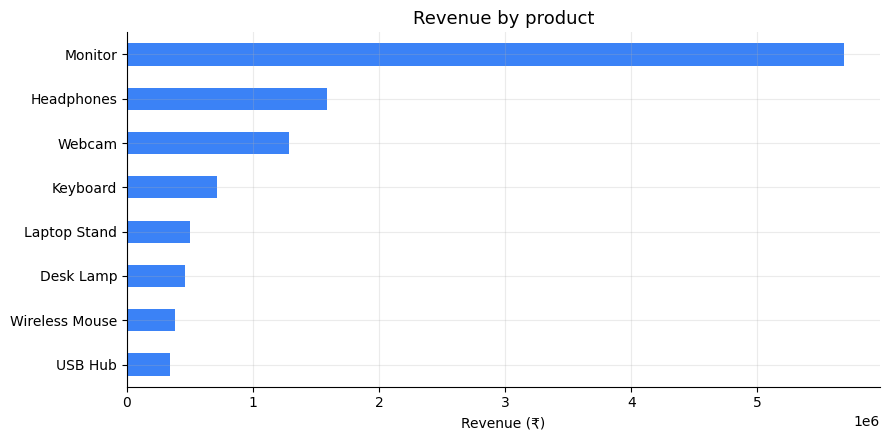

In [10]:
top_products = (df.groupby("Product_Name")
                  .agg(Revenue=("Order_Value", "sum"), Units=("Quantity", "sum"), Orders=("Order_ID", "count"))
                  .sort_values("Revenue", ascending=False)
                  .head(10))
top_products["Revenue_Share_%"] = top_products["Revenue"] / total_revenue * 100
display(top_products)

ax = top_products["Revenue"].sort_values().plot(kind="barh", color="#3b82f6")
ax.set_title("Revenue by product"); ax.set_xlabel("Revenue (₹)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [11]:
# Bonus: top 10 customers by spend
top_customers = (df.groupby("Customer_ID")
                   .agg(Revenue=("Order_Value", "sum"), Orders=("Order_ID", "count"))
                   .sort_values("Revenue", ascending=False).head(10))
top_customers

,Revenue,Orders
Customer_ID,,
CU00130,"192,285.00",2
CU00272,"188,372.00",7
CU00174,"181,592.00",1
CU00293,"161,887.00",2
CU00009,"144,786.00",4
CU00029,"144,094.00",2
CU00032,"113,790.00",5
CU00242,"109,881.00",3
CU00336,"107,693.00",4


## Task 8 · Rank product categories by total quantity sold and total revenue

,Total_Quantity,Total_Revenue,Orders,Qty_Rank,Revenue_Rank,Revenue_Share_%
Category,,,,,,
Electronics,1139,"8,564,211.00",380,1,1,78.09
Office,709,"1,217,591.00",246,3,2,11.10
Accessories,780,"722,020.00",259,2,3,6.58
Home,362,"462,638.00",115,4,4,4.22


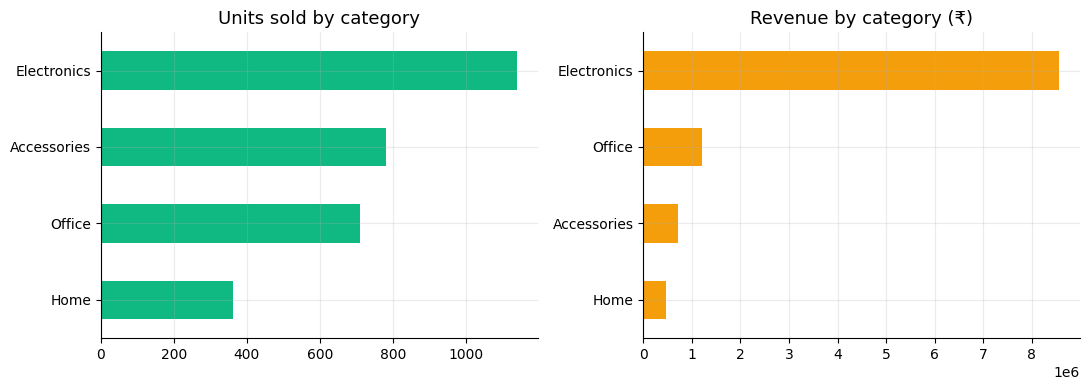

In [12]:
category_summary = (df.groupby("Category")
                      .agg(Total_Quantity=("Quantity", "sum"), Total_Revenue=("Order_Value", "sum"), Orders=("Order_ID", "count")))
category_summary["Qty_Rank"]     = category_summary["Total_Quantity"].rank(ascending=False).astype(int)
category_summary["Revenue_Rank"] = category_summary["Total_Revenue"].rank(ascending=False).astype(int)
category_summary["Revenue_Share_%"] = category_summary["Total_Revenue"] / total_revenue * 100
category_summary = category_summary.sort_values("Total_Revenue", ascending=False)
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
category_summary["Total_Quantity"].sort_values().plot(kind="barh", ax=axes[0], color="#10b981", title="Units sold by category")
category_summary["Total_Revenue"].sort_values().plot(kind="barh", ax=axes[1], color="#f59e0b", title="Revenue by category (₹)")
for a in axes: a.set_ylabel("")
plt.tight_layout(); plt.show()

## Task 9 · Average order value across payment methods

,Orders,Average_Order_Value,Median_Order_Value,Total_Revenue
Payment_Method,,,,
UPI,182,"13,205.07","4,446.50","2,403,323.00"
Credit Card,192,"12,862.86","4,697.50","2,469,669.00"
Net Banking,191,"10,366.33","4,497.00","1,979,969.00"
Cash,218,"9,639.35","3,847.50","2,101,378.00"
Debit Card,217,"9,272.45","3,996.00","2,012,121.00"


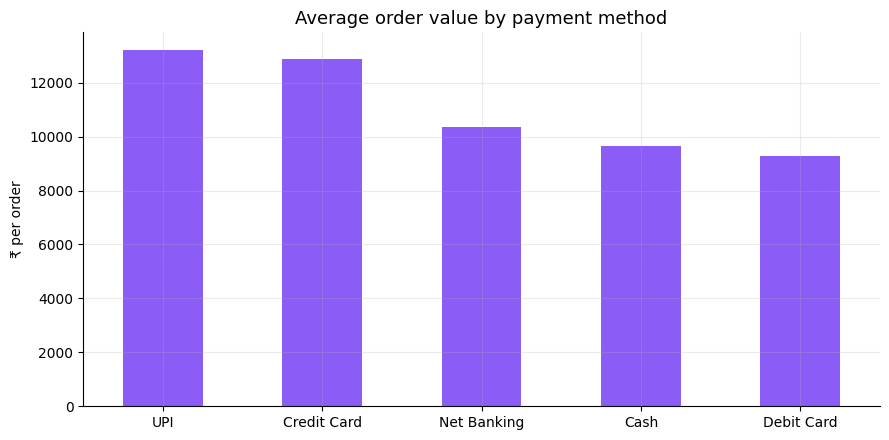

In [13]:
payment = (df.groupby("Payment_Method")["Order_Value"]
             .agg(Orders="count", Average_Order_Value="mean", Median_Order_Value="median", Total_Revenue="sum")
             .sort_values("Average_Order_Value", ascending=False))
display(payment)

ax = payment["Average_Order_Value"].plot(kind="bar", color="#8b5cf6", rot=0)
ax.set_title("Average order value by payment method"); ax.set_ylabel("₹ per order"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Task 10 · Busiest shopping days and peak sales month
Because the data spans **more than one calendar year**, months are analysed as `Year-Month` (e.g. 2025-03) so that March 2025 and March 2026 are not mixed.

In [14]:
weekday_summary = (df.groupby("Weekday", observed=True)
                     .agg(Orders=("Order_ID", "count"), Revenue=("Order_Value", "sum")))
display(weekday_summary.sort_values("Orders", ascending=False))
print("🗓  Busiest weekday (orders):", weekday_summary["Orders"].idxmax(),
      "| highest-revenue weekday:", weekday_summary["Revenue"].idxmax())

busiest_dates = (df.groupby("Order_Date")
                   .agg(Orders=("Order_ID", "count"), Revenue=("Order_Value", "sum"))
                   .sort_values(["Orders", "Revenue"], ascending=False).head(10))
print("\nTop 10 busiest individual dates")
display(busiest_dates)

,Orders,Revenue
Weekday,,
Saturday,157,"1,683,548.00"
Sunday,150,"1,905,099.00"
Monday,149,"1,622,647.00"
Thursday,147,"1,492,560.00"
Tuesday,138,"1,574,078.00"
Friday,137,"1,590,891.00"
Wednesday,122,"1,097,637.00"


🗓  Busiest weekday (orders): Saturday | highest-revenue weekday: Sunday

Top 10 busiest individual dates


,Orders,Revenue
Order_Date,,
2025-05-18,6,"52,282.00"
2025-03-31,6,"29,585.00"
2026-06-28,6,"25,674.00"
2026-05-09,5,"101,583.00"
2025-03-21,5,"93,287.00"
2026-08-27,5,"71,581.00"
2025-06-30,5,"68,890.00"
2026-05-30,5,"59,084.00"
2026-10-25,5,"58,293.00"


📈 Peak sales month: 2026-06  ->  ₹882,146


,Orders,Units,Revenue
Year_Month,,,
2026-06,50,204,"882,146.00"
2025-09,41,120,"651,680.00"
2025-01,51,169,"647,131.00"
2026-08,52,158,"643,142.00"
2026-01,55,165,"609,935.00"


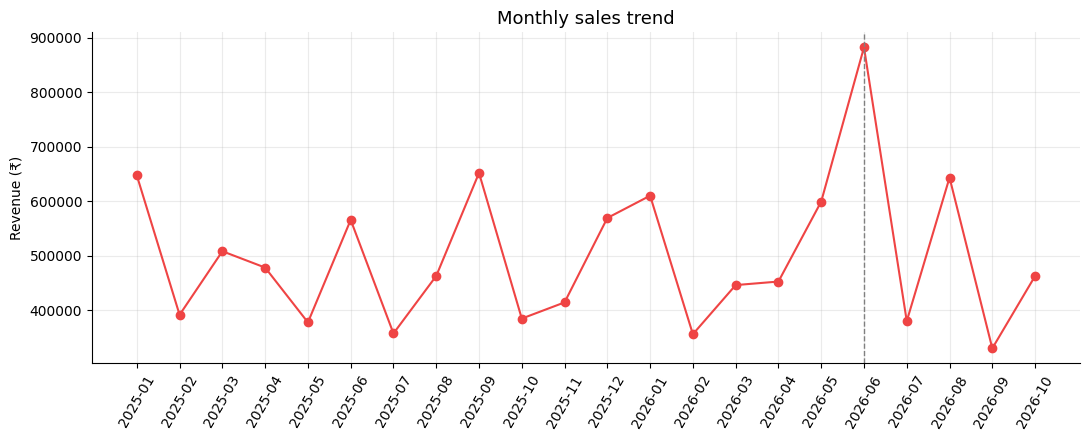

In [15]:
monthly = (df.groupby("Year_Month")
             .agg(Orders=("Order_ID", "count"), Units=("Quantity", "sum"), Revenue=("Order_Value", "sum")))
peak_month = monthly["Revenue"].idxmax()
print(f"📈 Peak sales month: {peak_month}  ->  {inr(monthly.loc[peak_month, 'Revenue'])}")
display(monthly.sort_values("Revenue", ascending=False).head(5))

ax = monthly["Revenue"].plot(marker="o", color="#ef4444", figsize=(11, 4.5))
ax.axvline(list(monthly.index).index(peak_month), color="grey", ls="--", lw=1)
ax.set_title("Monthly sales trend"); ax.set_ylabel("Revenue (₹)"); ax.set_xlabel("")
plt.xticks(range(len(monthly)), monthly.index, rotation=60); plt.tight_layout(); plt.show()

In [16]:
# Calendar-month view (Jan–Dec averaged over the years in which that month appears)
cal = (df.groupby(["Year", "Month", "Month_Name"])["Order_Value"].sum().reset_index()
         .groupby(["Month", "Month_Name"])["Order_Value"].mean().rename("Avg_Monthly_Revenue").reset_index())
cal.set_index("Month_Name")[["Avg_Monthly_Revenue"]]

,Avg_Monthly_Revenue
Month_Name,
January,"628,533.00"
February,"373,503.50"
March,"476,914.00"
April,"465,161.50"
May,"488,260.00"
June,"723,838.00"
July,"368,400.00"
August,"552,894.50"
September,"490,731.00"


---
# Part C — Core Python concepts
## Task 11 · Dictionary of category sales and a set of unique categories

In [17]:
sales_by_category = df.groupby("Category")["Order_Value"].sum().round(2).to_dict()      # dictionary
unique_categories = set(df["Category"])                                                # set

print("Dictionary – total sales by category:")
for cat, val in sorted(sales_by_category.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {cat:<12} {inr(val):>14}")

print("\nSet – unique categories:", unique_categories)
print("Number of unique categories:", len(unique_categories))

Dictionary – total sales by category:
  Electronics      ₹8,564,211
  Office           ₹1,217,591
  Accessories        ₹722,020
  Home               ₹462,638

Set – unique categories: {'Office', 'Accessories', 'Home', 'Electronics'}
Number of unique categories: 4


## Task 12 · Function returning the total sales for a category

In [18]:
def category_sales(category, data=df):
    """Return total sales (₹) of one category from the cleaned data.
    Case-insensitive; raises a helpful error for unknown categories."""
    match = {c.lower(): c for c in data["Category"].unique()}
    key = str(category).strip().lower()
    if key not in match:
        raise ValueError(f"Unknown category '{category}'. Choose from: {sorted(match.values())}")
    return data.loc[data["Category"] == match[key], "Order_Value"].sum()

for c in sorted(unique_categories):
    print(f"{c:<12} {inr(category_sales(c))}")

# the function must agree with the dictionary above
assert all(np.isclose(category_sales(c), v) for c, v in sales_by_category.items())

try:
    category_sales("Toys")
except ValueError as e:
    print("\nError handling works ->", e)

Accessories  ₹722,020
Electronics  ₹8,564,211
Home         ₹462,638
Office       ₹1,217,591

Error handling works -> Unknown category 'Toys'. Choose from: ['Accessories', 'Electronics', 'Home', 'Office']


---
# Part D — NumPy statistics & outliers
## Task 13 · Mean, median and standard deviation of `Order_Value`

In [19]:
values = df["Order_Value"].to_numpy()

stats = {"Mean": np.mean(values), "Median": np.median(values), "Std deviation": np.std(values, ddof=1),
         "Min": values.min(), "Max": values.max()}
pd.Series(stats).map(inr).to_frame("Order_Value")

,Order_Value
Mean,"₹10,966"
Median,"₹4,198"
Std deviation,"₹18,818"
Min,₹299
Max,"₹181,592"


**Reading the result:** the mean is well above the median and the standard deviation is large — a **right-skewed** distribution: most orders are modest, but a smaller number of big orders (expensive products and/or bulk quantities) pull the average up. The median is therefore the better "typical order" figure.

## Task 14 · Unusually high orders (IQR method) and order-value bands

**IQR rule:** `IQR = Q3 − Q1`; an order is an outlier if `Order_Value > Q3 + 1.5 × IQR`.
**Bands (documented rule, quartile based):** Low ≤ Q1 · Medium between Q1 and Q3 · High > Q3.

In [20]:
q1, q3 = np.percentile(values, [25, 75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Q1 = {inr(q1)} | Q3 = {inr(q3)} | IQR = {inr(iqr)}")
print(f"Upper fence = {inr(upper_fence)}   (lower fence {inr(lower_fence)} is below zero, so no low outliers are possible)")

outliers = df[df["Order_Value"] > upper_fence].sort_values("Order_Value", ascending=False)
share_orders  = len(outliers) / len(df) * 100
share_revenue = outliers["Order_Value"].sum() / total_revenue * 100
print(f"\nOutlier orders: {len(outliers)} ({share_orders:.1f}% of orders) generating {share_revenue:.1f}% of revenue")

display(outliers[["Order_ID", "Customer_ID", "Order_Date", "Product_Name", "Quantity", "Unit_Price", "Order_Value"]].head(15))
print("Products behind the outliers:"); display(outliers["Product_Name"].value_counts().to_frame("Outlier_Orders"))

Q1 = ₹1,998 | Q3 = ₹10,794 | IQR = ₹8,796
Upper fence = ₹23,988   (lower fence ₹-11,196 is below zero, so no low outliers are possible)

Outlier orders: 107 (10.7% of orders) generating 54.0% of revenue


,Order_ID,Customer_ID,Order_Date,Product_Name,Quantity,Unit_Price,Order_Value
731,OR000740,CU00174,2026-08-15,Monitor,8,"22,699.00","181,592.00"
412,OR000135,CU00293,2026-04-22,Monitor,5,"30,299.00","151,495.00"
155,OR000440,CU00029,2026-06-07,Monitor,5,"28,299.00","141,495.00"
446,OR000351,CU00130,2026-01-05,Monitor,6,"23,499.00","140,994.00"
275,OR000394,CU00140,2026-07-26,Monitor,6,"17,899.00","107,394.00"
585,OR000115,CU00032,2025-01-26,Monitor,4,"25,999.00","103,996.00"
588,OR000287,CU00272,2025-01-26,Monitor,7,"14,799.00","103,593.00"
957,OR000294,CU00133,2026-05-08,Monitor,5,"19,799.00","98,995.00"
160,OR000174,CU00396,2025-09-11,Monitor,9,"10,699.00","96,291.00"
71,OR000683,CU00290,2025-01-04,Monitor,6,"15,399.00","92,394.00"


Products behind the outliers:


,Outlier_Orders
Product_Name,
Monitor,77
Headphones,21
Webcam,7
Keyboard,2


,Orders,Revenue,Avg_Order_Value,Revenue_Share_%
Order_Band,,,,
Low,253,"307,733.00","1,216.34",2.81
Medium,498,"2,463,730.00","4,947.25",22.47
High,249,"8,194,997.00","32,911.63",74.73


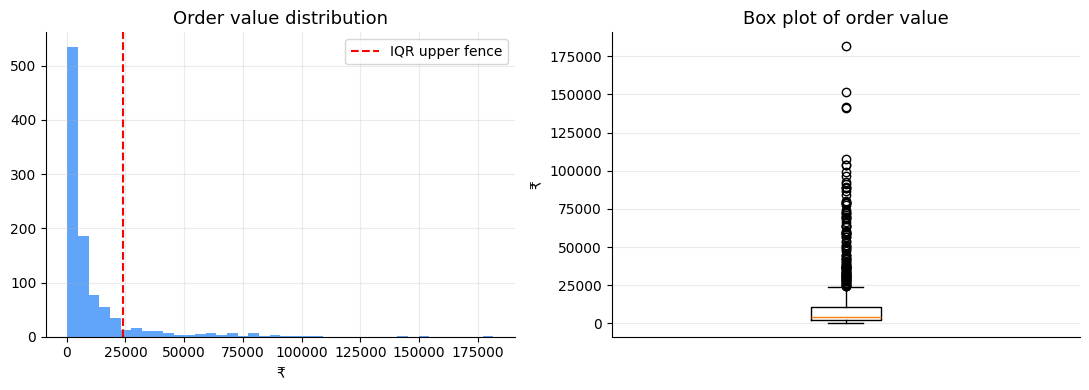

In [21]:
def order_band(v):
    """Low: <= Q1 | Medium: Q1 < v <= Q3 | High: > Q3"""
    if v <= q1:  return "Low"
    if v <= q3:  return "Medium"
    return "High"

df["Order_Band"] = pd.Categorical(df["Order_Value"].apply(order_band), categories=["Low", "Medium", "High"], ordered=True)

bands = df.groupby("Order_Band", observed=True).agg(Orders=("Order_ID", "count"), Revenue=("Order_Value", "sum"),
                                                    Avg_Order_Value=("Order_Value", "mean"))
bands["Revenue_Share_%"] = bands["Revenue"] / total_revenue * 100
display(bands)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(values, bins=40, color="#60a5fa"); axes[0].axvline(upper_fence, color="red", ls="--", label="IQR upper fence")
axes[0].set_title("Order value distribution"); axes[0].set_xlabel("₹"); axes[0].legend()
axes[1].boxplot(values, showfliers=True); axes[1].set_title("Box plot of order value"); axes[1].set_ylabel("₹"); axes[1].set_xticks([])
plt.tight_layout(); plt.show()

**Note:** the catalogue mixes low-priced items (₹300–₹3,000) with premium ones (monitors, headphones), so a single IQR fence for the whole store flags many *Monitor / bulk* orders. This is a genuine business pattern, not a data error. A stricter alternative is to compute the fence **per category** (shown below).

In [22]:
def iqr_outliers_by_group(data, group_col):
    rows = []
    for g, sub in data.groupby(group_col, observed=True):
        a, b = np.percentile(sub["Order_Value"], [25, 75])
        fence = b + 1.5 * (b - a)
        rows.append({group_col: g, "Upper_Fence": fence, "Outlier_Orders": int((sub["Order_Value"] > fence).sum()), "Orders": len(sub)})
    return pd.DataFrame(rows).set_index(group_col)

iqr_outliers_by_group(df, "Category")

,Upper_Fence,Outlier_Orders,Orders
Category,,,
Accessories,"7,492.75",15,259
Electronics,"62,955.00",35,380
Home,"11,039.75",6,115
Office,"13,441.50",15,246


---
# Part E — OOP and recommendations
## Task 15 · A simple `Product` class

In [23]:
class Product:
    """A catalogue product with a name and a (typical) price."""

    def __init__(self, name, price, category=None):
        self.name = name
        self.price = float(price)
        self.category = category

    def total_for(self, quantity):
        """Value of buying `quantity` units at this price."""
        return self.price * quantity

    def __repr__(self):
        return f"Product(name='{self.name}', price={self.price:,.2f}, category='{self.category}')"

# Build the catalogue from the cleaned data (price = median selling price per product)
cat_lookup = df.groupby("Product_Name")["Category"].first()
median_price = df.groupby("Product_Name")["Unit_Price"].median()
catalogue = [Product(n, median_price[n], cat_lookup[n]) for n in median_price.index]

for p in sorted(catalogue, key=lambda p: p.price, reverse=True):
    print(p, f"| 3 units = {inr(p.total_for(3))}")

Product(name='Monitor', price=14,999.00, category='Electronics') | 3 units = ₹44,997
Product(name='Headphones', price=3,449.00, category='Electronics') | 3 units = ₹10,347
Product(name='Webcam', price=2,899.00, category='Electronics') | 3 units = ₹8,697
Product(name='Keyboard', price=1,699.00, category='Office') | 3 units = ₹5,097
Product(name='Desk Lamp', price=1,299.00, category='Home') | 3 units = ₹3,897
Product(name='Laptop Stand', price=1,199.00, category='Office') | 3 units = ₹3,597
Product(name='Wireless Mouse', price=899.00, category='Accessories') | 3 units = ₹2,697
Product(name='USB Hub', price=799.00, category='Accessories') | 3 units = ₹2,397


### Five data-driven recommendations
The figures below are calculated from the cleaned data, so they update automatically if the dataset changes.

In [24]:
cat_rev   = category_summary["Total_Revenue"]
top_cat   = cat_rev.idxmax()
low_cat   = cat_rev.idxmin()
units_top_cat = category_summary.loc[top_cat, "Total_Quantity"] / total_units * 100
top_prod  = top_products["Revenue"].idxmax()
low_prod  = top_products["Revenue"].idxmin()
best_day  = weekday_summary["Orders"].idxmax()
low_day   = weekday_summary["Orders"].idxmin()
best_pay  = payment["Average_Order_Value"].idxmax()
worst_pay = payment["Average_Order_Value"].idxmin()
high_band_share = bands.loc["High", "Revenue_Share_%"]
slow_month = monthly["Revenue"].idxmin()

recommendations = [
    f"1. Protect the revenue engine – '{top_cat}' brings {cat_rev[top_cat]/total_revenue*100:.1f}% of revenue from {units_top_cat:.1f}% of units, "
    f"and '{top_prod}' is the #1 product ({top_products.loc[top_prod, 'Revenue_Share_%']:.1f}% of revenue). Keep these always in stock and feature them on the home page and in ads.",
    f"2. Lift the weak spots – '{low_cat}' (lowest category) and '{low_prod}' (lowest product) contribute the least. Bundle them with best-sellers "
    f"(e.g. '{top_prod}' + a '{low_prod}') or run targeted discounts to raise attach rate.",
    f"3. Time campaigns to demand – {best_day} is the busiest weekday and {low_day} the quietest; peak revenue came in {peak_month} while {slow_month} was the weakest month. "
    f"Schedule flash sales on {low_day}, and build inventory/staffing ahead of peak periods.",
    f"4. Use payment offers strategically – '{best_pay}' orders are the largest on average ({inr(payment.loc[best_pay, 'Average_Order_Value'])}) versus "
    f"{inr(payment.loc[worst_pay, 'Average_Order_Value'])} for '{worst_pay}'. Offer cashback / easy-EMI on high-ticket baskets and nudge small-basket users toward add-ons or free-shipping thresholds.",
    f"5. Look after high-value orders – the top quartile of orders (High band) delivers {high_band_share:.1f}% of revenue, and {len(outliers)} outlier orders alone give {share_revenue:.1f}%. "
    f"Offer these customers priority dispatch, loyalty rewards and fraud/stock checks before shipping.",
]
for r in recommendations:
    print(r, "\n")

1. Protect the revenue engine – 'Electronics' brings 78.1% of revenue from 38.1% of units, and 'Monitor' is the #1 product (51.9% of revenue). Keep these always in stock and feature them on the home page and in ads. 

2. Lift the weak spots – 'Home' (lowest category) and 'USB Hub' (lowest product) contribute the least. Bundle them with best-sellers (e.g. 'Monitor' + a 'USB Hub') or run targeted discounts to raise attach rate. 

3. Time campaigns to demand – Saturday is the busiest weekday and Wednesday the quietest; peak revenue came in 2026-06 while 2026-09 was the weakest month. Schedule flash sales on Wednesday, and build inventory/staffing ahead of peak periods. 

4. Use payment offers strategically – 'UPI' orders are the largest on average (₹13,205) versus ₹9,272 for 'Debit Card'. Offer cashback / easy-EMI on high-ticket baskets and nudge small-basket users toward add-ons or free-shipping thresholds. 

5. Look after high-value orders – the top quartile of orders (High band) delive

> 🔎 **Caution:** these are *associations* in the sample provided, not proof of cause and effect. Validate any pricing or campaign change with a small A/B test before rolling it out.

---
# 💾 Save the deliverables
Writes the cleaned dataset, outlier list, summary tables and a short text report, then offers them for download.

In [25]:
import os
os.makedirs("outputs", exist_ok=True)

df.drop(columns=["Order_Band"]).to_csv("outputs/21_retail_orders_cleaned.csv", index=False)
outliers.to_csv("outputs/21_high_value_order_outliers.csv", index=False)
top_products.to_csv("outputs/21_top_products.csv")
category_summary.to_csv("outputs/21_category_summary.csv")
monthly.to_csv("outputs/21_monthly_sales_trend.csv")

with open("outputs/21_summary_report.txt", "w", encoding="utf-8") as f:
    f.write("PROJECT 21 - ONLINE RETAIL CUSTOMER PURCHASE ANALYSIS\n" + "=" * 54 + "\n")
    f.write(f"Rows after cleaning : {len(df):,}\nTotal orders        : {total_orders:,}\nTotal units sold    : {total_units:,}\n")
    f.write(f"Total revenue       : {inr(total_revenue)}\nPeak month          : {peak_month}\nBusiest weekday     : {best_day}\n")
    f.write(f"Mean / Median order : {inr(np.mean(values))} / {inr(np.median(values))}\n")
    f.write(f"IQR outlier orders  : {len(outliers)} (upper fence {inr(upper_fence)})\n\nRECOMMENDATIONS\n")
    f.write("\n".join(recommendations))

print("Files saved in ./outputs :", os.listdir("outputs"))

Files saved in ./outputs : ['21_category_summary.csv', '21_retail_orders_cleaned.csv', '21_summary_report.txt', '21_top_products.csv', '21_monthly_sales_trend.csv', '21_high_value_order_outliers.csv']


In [26]:
# Download everything as one zip (works in Google Colab; skipped elsewhere)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("project21_outputs", "zip", "outputs")
    files.download("project21_outputs.zip")
except ImportError:
    print("Not running in Colab – find the files in the 'outputs' folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>